In [1]:
import numpy as n
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import sys
import astropy as ast
from astropy.io import ascii
from astropy.table import Table
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.path as mpath
from pathlib import Path
import lightkurve as lk
from astropy.timeseries import LombScargle
from metrics import fit_plotter_flux, compute_lomb_scargle, plot_periodogram, info, plot_phase_fold_binned, plot_phase_fold
from view_and_clean import offset_corrector
%matplotlib widget
from Pyriod import Pyriod

/opt/anaconda3/envs/ysg/lib/python3.13/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.3.0) or chardet (7.4.3)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(
/opt/anaconda3/envs/ysg/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


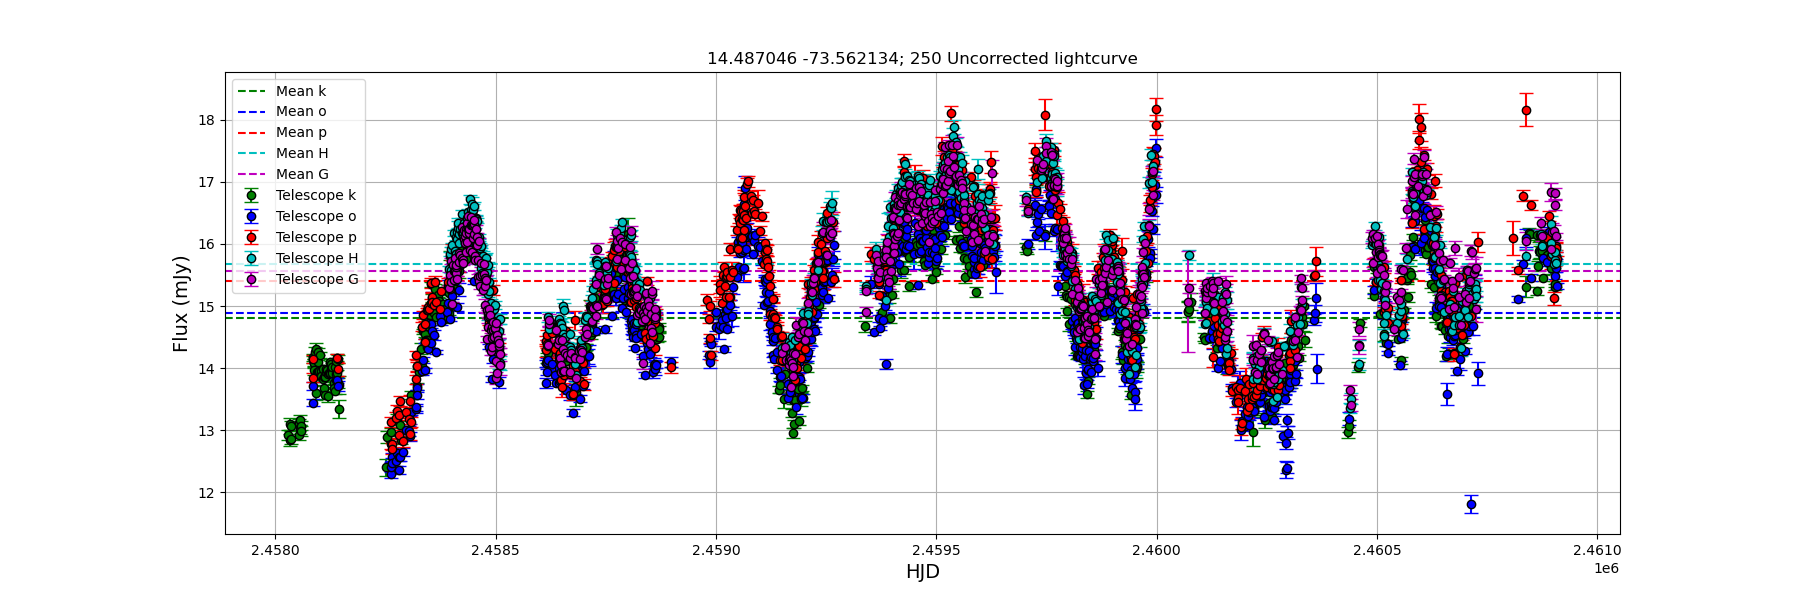

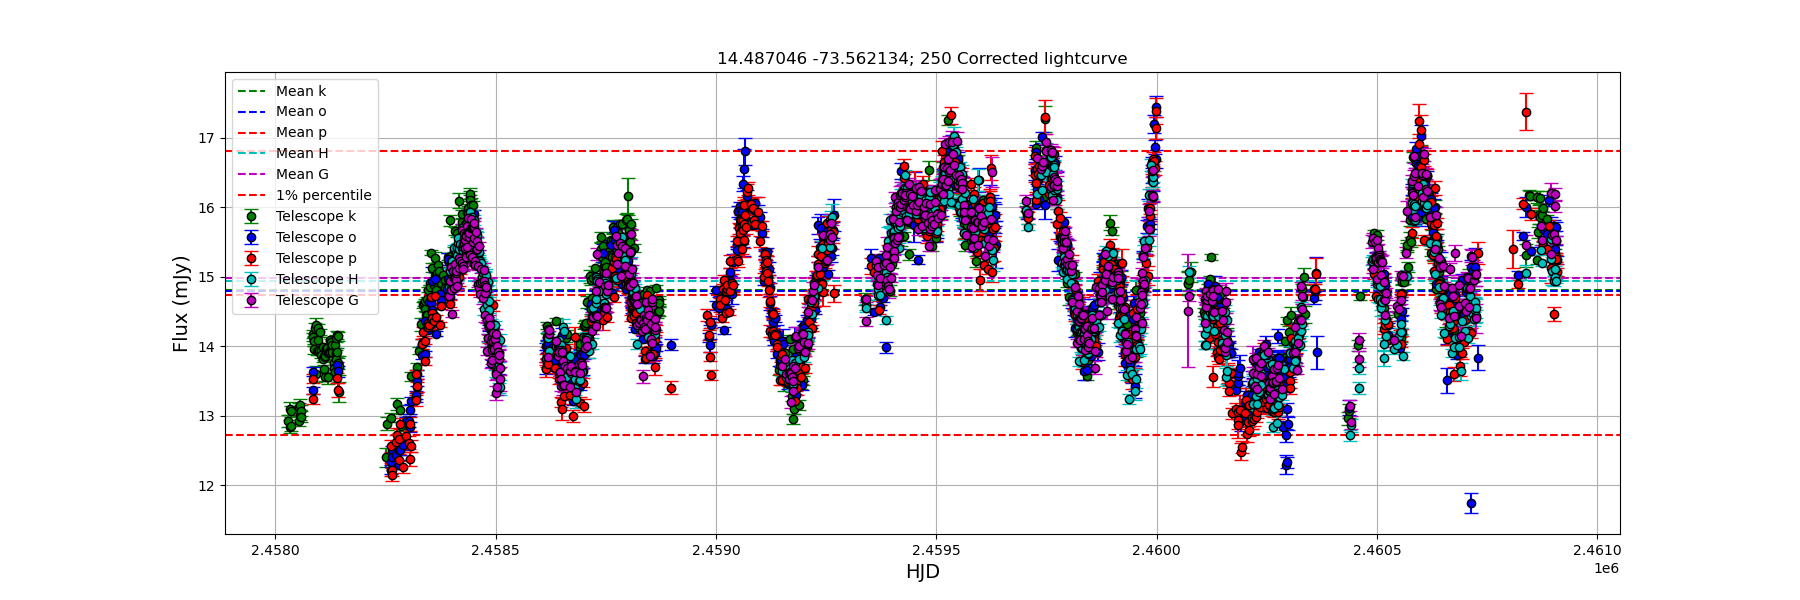

In [2]:
index = 250
df, telescopes = offset_corrector(index)
lc = lk.LightCurve(time=df['HJD'], flux=df['flux_(mJy)'], flux_err=df['flux_err'])

In [3]:
pyriod = Pyriod(lc, amp_unit='relative', freq_unit='per day')
pyriod.Pyriod()

In [4]:
1/0.000546255

1830.6468590676513

In [5]:
1/0.000961053

1040.5253404338782

In [7]:
1/0.004551812

219.69272896156522

In [ ]:
index = 250
df = pd.read_csv(f'pyriod_results/{index}_Pyriod_solution.csv')
df['period'] = 1/df['freq']
for i in df['period']:
    print(f"{i:.0f}")
# print(df['period'])
df.to_csv(f'pyriod_results/{index}_Pyriod_solution_with_period.csv', index=False)

215
184
295
288
245
371
292
295
294
295
295
295


In [5]:
df = pd.read_csv('Pyriod_solution.csv')
df['period'] = 1/df['freq']
for i in df['period']:
    print(f"{i:.0f}")
# print(df['period'])
# df.to_csv(f'pyriod_results/{index}_Pyriod_solution_with_period.csv', index=False)

215
184
288
245
371
292
295
294
295
295
295


Best frequency: 0.020519 1/day, Best period: 48.74 days, Max power: 0.119, False alarm probability: 3.026e-42
False alarm level for 1.0%: 1.687e-02
Best frequency: 0.020523 1/day, Best period: 48.73 days, Max power: 0.119, False alarm probability: 3.065e-42
False alarm level for 1.0%: 1.687e-02
Grid sampled at 42125 points


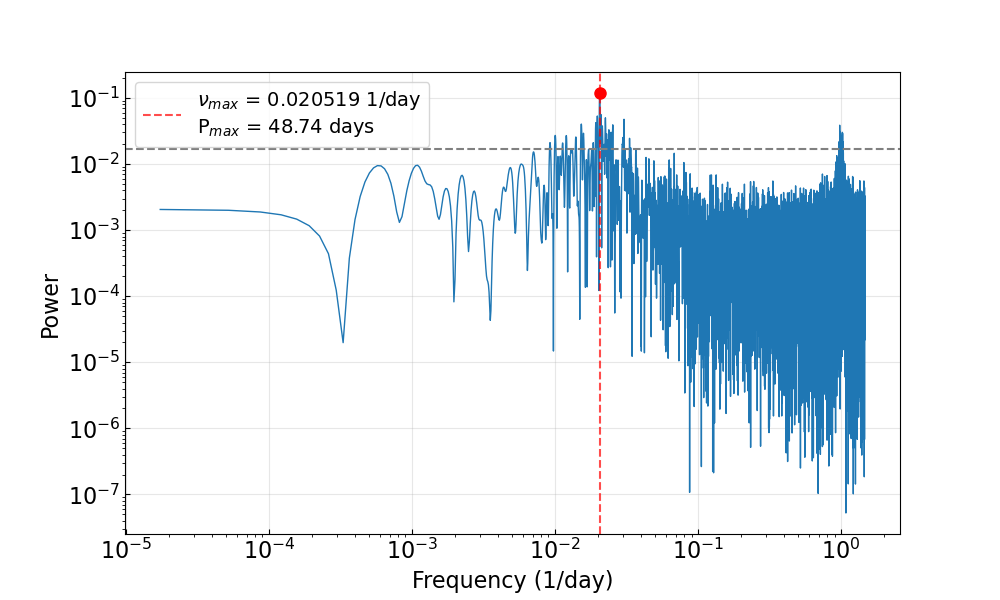

Grid sampled at 151532 points


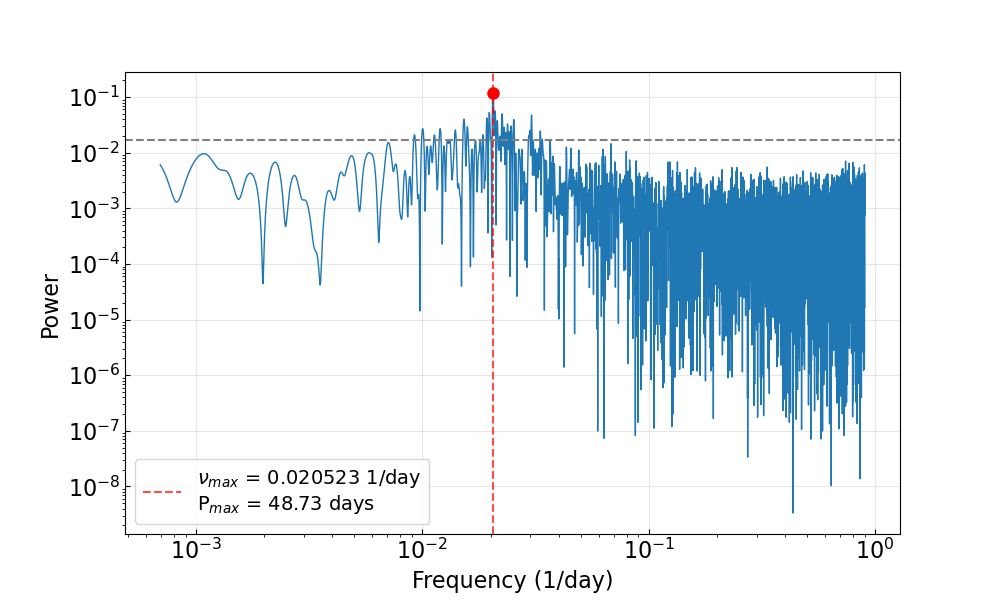

In [11]:
index = 780
lombs1 = compute_lomb_scargle(index, auto=True)#, samples_per_peak=10)
lombs2 = compute_lomb_scargle(index, samples_per_peak=100)
plot_periodogram(index, lombs1['frequency'], lombs1['power'], lombs1['best_frequency'], lombs1['false_alarm_level'], lombs1['peaks'], lombs1['observation_period'], show_best=True)
plot_periodogram(index, lombs2['frequency'], lombs2['power'], lombs2['best_frequency'], lombs2['false_alarm_level'], lombs2['peaks'], lombs2['observation_period'], show_best=True)

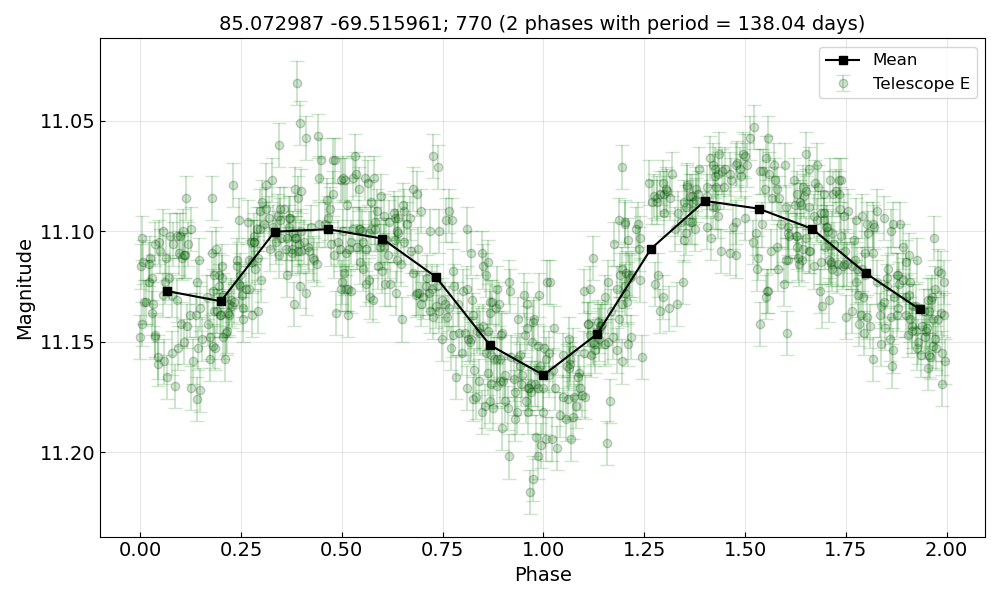

Average scatter (amplitude) per 10 point phase bin: 6.687 mJy


In [7]:
phase_fold = plot_phase_fold_binned(index, best_period=1/lombs2['best_frequency'], mag_space=True)

Best frequency: 0.000929 1/day, Best period: 1075.86 days, Max power: 0.200, False alarm probability: 1.057e-139
False alarm level for 1.0%: 9.894e-03
Grid sampled at 26844 points


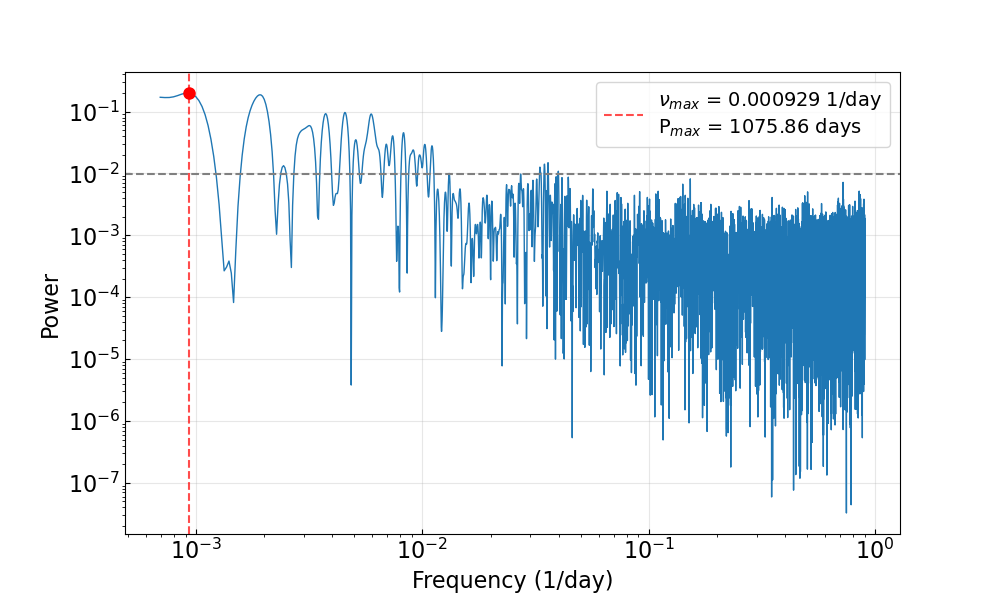

In [9]:
index = 250
lombs1 = compute_lomb_scargle(index)#, samples_per_peak=10)
# lombs2 = compute_lomb_scargle(index, samples_per_peak=100)
plot_periodogram(index, lombs1['frequency'], lombs1['power'], lombs1['best_frequency'], lombs1['false_alarm_level'], lombs1['peaks'], lombs1['observation_period'], show_best=True)
# plot_periodogram(index, lombs2['frequency'], lombs2['power'], lombs2['best_frequency'], lombs2['false_alarm_level'], lombs2['peaks'], lombs2['observation_period'], show_best=True)

In [10]:
1/1.92e-3

520.8333333333334

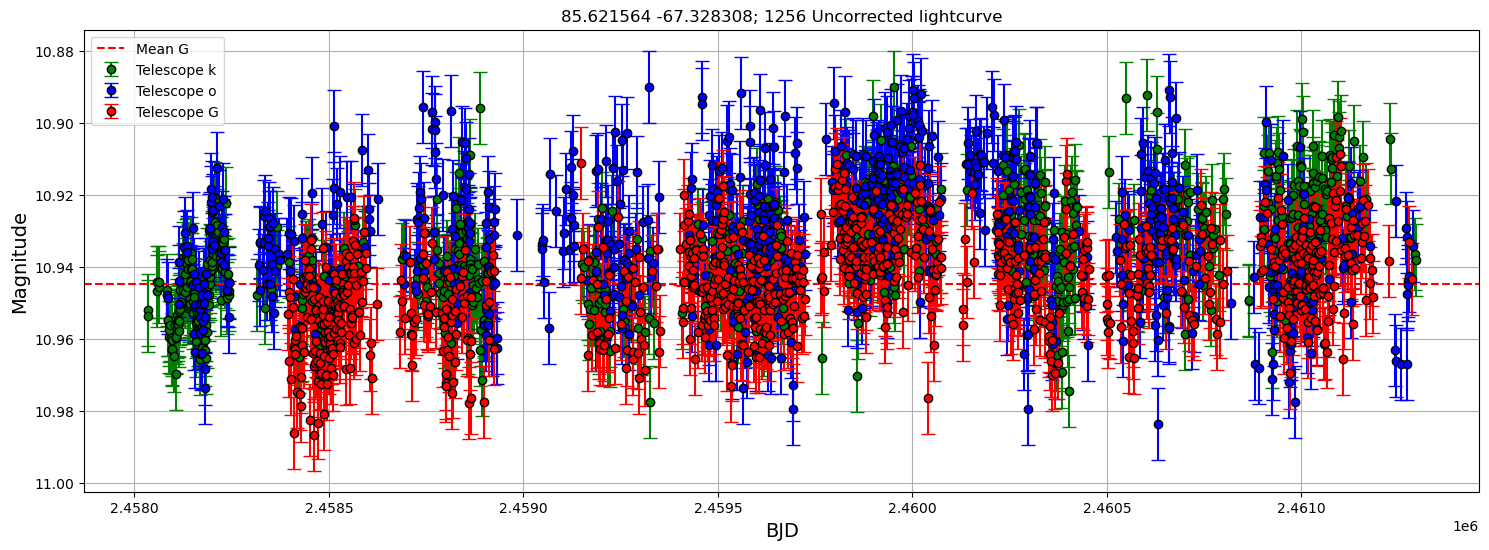

Best frequency: 0.002503 1/day, Best period: 399.44 days, Max power: 0.090, False alarm probability: 1.540e-45
False alarm level for 1.0%: 1.203e-02
Grid sampled at 21891 points


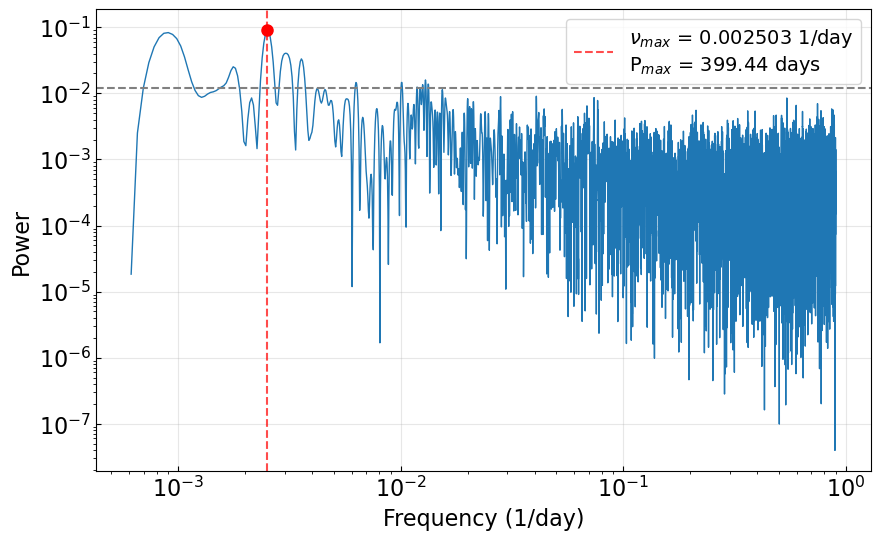

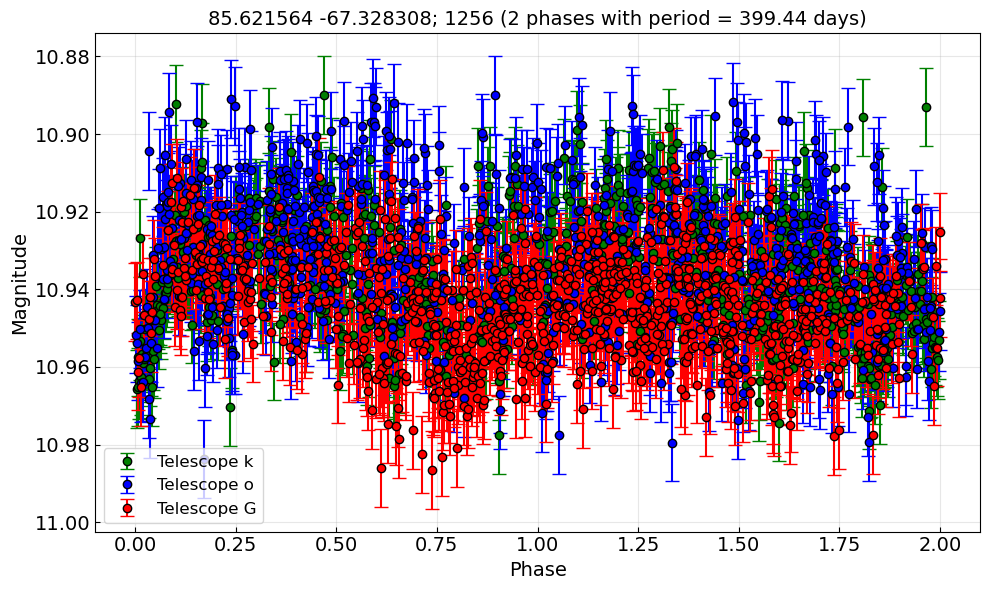

Average scatter (amplitude) per 10 point phase bin: 6.133 mJy


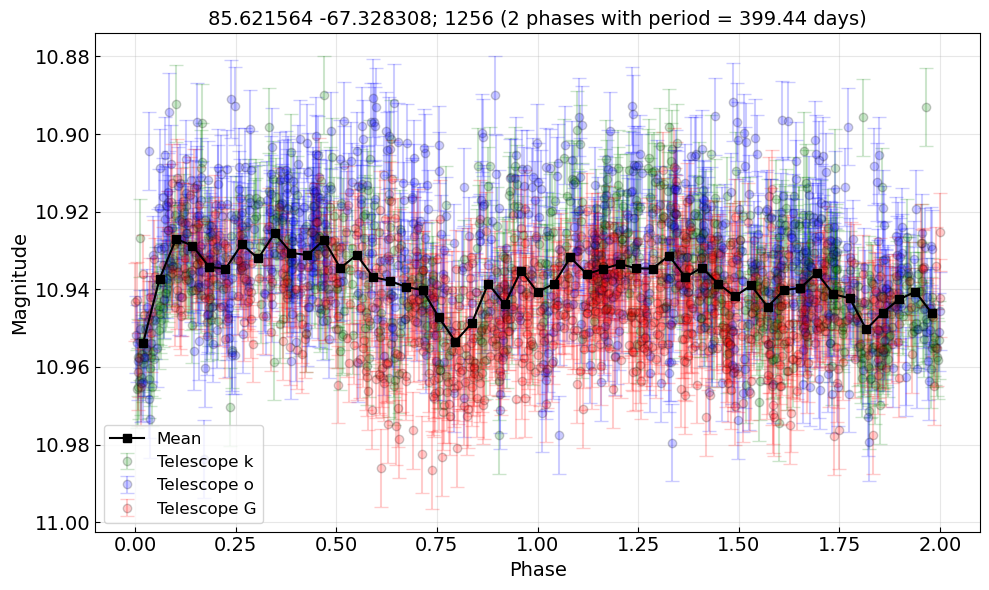

Average scatter (amplitude) per 10 point phase bin: 6.133 mJy
[0.00090111 0.00176393 0.00250349 0.00303762 0.00357174 0.00628346
 0.01010452 0.01183016 0.01289841]
Amplitude metrics:
	Lower 5% percentile: -3.48 mJy, 10.91 mags
	Upper 5% percentile: 4.15 mJy, 10.96 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 5% of data) (g-band: True): 7.63 mJy, 0.05 mags
Amplitude metrics:
	Lower 1% percentile: -4.78 mJy, 10.90 mags
	Upper 1% percentile: 5.81 mJy, 10.97 mags
	Percentile amplitude of variability (excluding the brightest and dimmest 1% of data) (g-band: True): 10.58 mJy, 0.07 mags
	Largest amplitude of variability (g-band: True): 13.63 mJy, 0.10 mags
	Average amplitude across all periods: 12.109 mJy
	Standard deviation of amplitudes: 0.559 mJy
	Average amplitude (12.109 mJy) is greater than 5 sigma (0.559 mJy). This indicates consistent variability across periods.


In [1]:
from metrics_newlcs_sept26 import info

info(1256)

In [ ]:
info